# Práctica 2.3 — Componentes principales: 15 privaciones en pocos números

Este cuaderno acompaña la clase «Componentes principales» (PCA, *Principal Component Analysis*) del tema 2.3. Como en K-means, no hay una variable Y: se busca **resumir muchas variables correlacionadas en pocas componentes** que guarden casi toda la información. Sigue el recorrido de la clase:

1. Datos y correlaciones · 2. **PCA a mano** con dos variables · 3. ¿Por qué escalar? · 4. **¿Cuántas componentes?** · 5. **Leer las cargas** · 6. El plano de los municipios · 7. **Un índice compuesto** frente al IPM y al promedio simple · 8. Estabilidad · 9. PCA + K-means

**Datos.** `datos/ej2_privaciones_ipm_2018.csv`: 1.122 municipios **reales**, con las 15 privaciones del IPM (índice de pobreza multidimensional) del DANE, censo 2018, en porcentaje de personas. Es la misma base de la práctica de K-means y del ejercicio 02.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

def encuadre(ax):
    """Encuadra el mapa en Colombia continental (San Andrés queda fuera del recuadro)."""
    ax.set_xlim(-79.3, -66.7); ax.set_ylim(-4.4, 12.6); ax.set_axis_off()

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

# Colores de los grupos, como en la clase: de azul (menos privación) a naranja (más), pasando por morado
MORADO = '#8a4fd1'
COL_G = [AZUL, MORADO, NARANJA]

## 1. Datos y correlaciones

In [3]:
df = pd.read_csv(DATOS / 'ej2_privaciones_ipm_2018.csv')
PRIV = list(df.columns[5:20])                     # las 15 privaciones del IPM
NOM = {'analfabetismo': 'Analfabetismo', 'bajo_logro_educativo': 'Bajo logro educativo', 'barreras_primera_infancia': 'Barreras primera infancia',
       'barreras_acceso_salud': 'Barreras acceso a salud', 'tasa_dependencia': 'Dependencia económica', 'hacinamiento_critico': 'Hacinamiento crítico',
       'inadecuada_elim_excretas': 'Sin manejo de excretas', 'inasistencia_escolar': 'Inasistencia escolar', 'paredes_inadecuadas': 'Paredes inadecuadas',
       'pisos_inadecuados': 'Pisos inadecuados', 'rezago_escolar': 'Rezago escolar', 'sin_agua_mejorada': 'Sin agua mejorada',
       'sin_aseguramiento_salud': 'Sin aseguramiento en salud', 'trabajo_infantil': 'Trabajo infantil', 'trabajo_informal': 'Trabajo informal'}
print(f'{len(df)} municipios, {len(PRIV)} privaciones; faltantes: {df[PRIV].isna().sum().sum()}')
df[PRIV].describe().T[['mean', 'std', 'min', 'max']].sort_values('std', ascending=False)

1122 municipios, 15 privaciones; faltantes: 0


,mean,std,min,max
inadecuada_elim_excretas,24.330,22.117,0.200,98.700
sin_agua_mejorada,27.114,21.929,0.200,99.000
pisos_inadecuados,15.701,16.829,0.000,86.700
tasa_dependencia,41.091,12.946,14.700,97.700
bajo_logro_educativo,66.962,12.675,18.300,96.200
paredes_inadecuadas,5.187,8.235,0.000,72.700
analfabetismo,17.427,8.024,2.000,52.500
rezago_escolar,19.040,7.700,5.300,62.100
hacinamiento_critico,11.162,7.492,1.400,58.100
trabajo_informal,87.584,6.829,58.700,100.000


Las 15 privaciones están en porcentaje, pero varían muy distinto: la eliminación inadecuada de excretas y la falta de agua mejorada tienen una desviación de unos 22 puntos, mientras que el trabajo infantil apenas 1,4 y las barreras de primera infancia 3,3. Esto importará en la sección 3.

105 pares: 102 con r positiva, 39 con r > 0,5; r promedio 0.388
Los tres pares más correlacionados:
barreras_primera_infancia  rezago_escolar            0.750
inasistencia_escolar       rezago_escolar            0.785
barreras_primera_infancia  sin_aseguramiento_salud   0.851


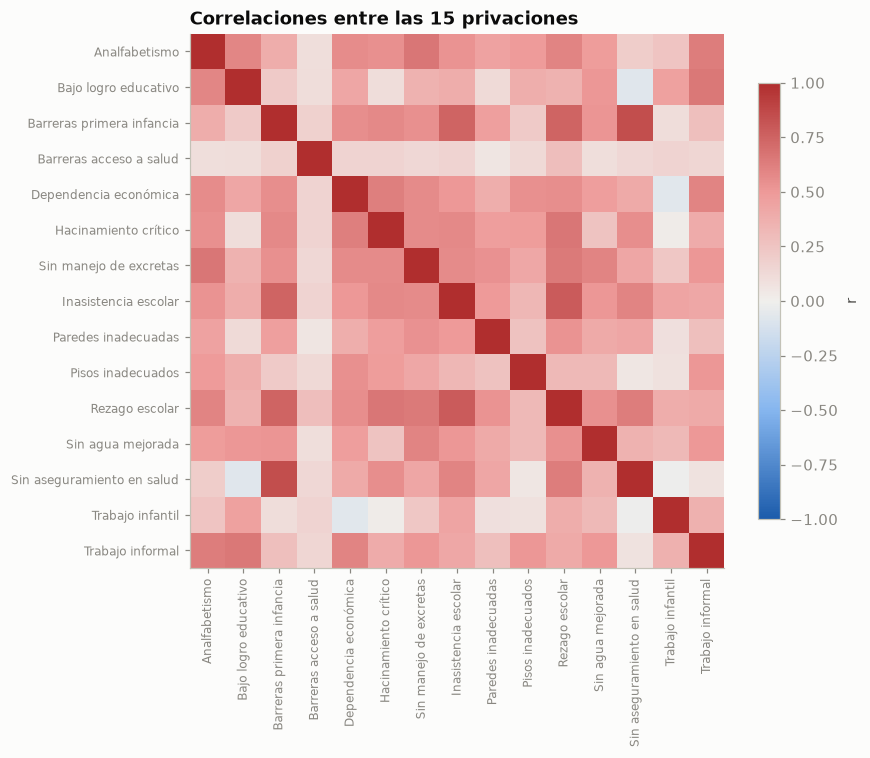

In [4]:
R = df[PRIV].corr()
pares = pd.Series({(a, b): R.loc[a, b] for i, a in enumerate(PRIV) for b in PRIV[i + 1:]})   # los 105 pares distintos
print(f'{len(pares)} pares: {(pares > 0).sum()} con r positiva, {(pares > .5).sum()} con r > 0,5; r promedio {pares.mean():.3f}')
print('Los tres pares más correlacionados:'); print(pares.sort_values().tail(3).round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(R, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(15), [NOM[p] for p in PRIV], rotation=90, fontsize=8); ax.set_yticks(range(15), [NOM[p] for p in PRIV], fontsize=8); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=.75, label='r'); ax.set_title('Correlaciones entre las 15 privaciones')
plt.tight_layout(); plt.show()

De los 105 pares de privaciones, **102 se mueven en la misma dirección** (r positiva) y 39 tienen una correlación mayor que 0,5; la r promedio es 0,388. Los pares más fuertes son barreras de primera infancia con sin aseguramiento en salud (0,851), inasistencia con rezago escolar (0,785) y barreras de primera infancia con rezago escolar (0,750). Hay mucha información repetida: eso es lo que PCA aprovecha.

## 2. PCA a mano con dos variables

Con rezago escolar e inasistencia escolar (las dos de la clase), escaladas. La primera componente es la dirección en la que los datos más varían: el autovector de la matriz de covarianzas con el autovalor más grande. El autovalor es la varianza a lo largo de esa dirección.

In [5]:
# PCA a mano con dos variables: autovectores de la matriz de covarianzas de las variables escaladas
D2 = ['rezago_escolar', 'inasistencia_escolar']
Z2 = StandardScaler().fit_transform(df[D2])
cov = np.cov(Z2, rowvar=False, ddof=0)            # con variables escaladas, es la matriz de correlaciones
val, vec = np.linalg.eigh(cov)
orden = val.argsort()[::-1]; val, vec = val[orden], vec[:, orden]
vec *= np.sign(vec.sum(axis=0))                    # el signo es arbitrario: lo fijamos para que PC1 suba con la privación
print(f'r = {cov[0, 1]:.3f}')
print(f'autovalores: {val.round(3)} · varianza explicada: {(val / val.sum()).round(3)}')
print(f'PC1 = {vec[0, 0]:.3f} · z_rezago + {vec[1, 0]:.3f} · z_inasistencia')
sk = PCA().fit(Z2)
print(f'scikit-learn: varianza explicada {sk.explained_variance_ratio_.round(3)}, cargas de PC1 {np.abs(sk.components_[0]).round(3)}')

r = 0.785
autovalores: [1.785 0.215] · varianza explicada: [0.892 0.108]
PC1 = 0.707 · z_rezago + 0.707 · z_inasistencia
scikit-learn: varianza explicada [0.892 0.108], cargas de PC1 [0.707 0.707]


Con r = 0,785, la primera componente tiene autovalor 1,785 y explica el **89,2 %** de la varianza de las dos variables: un solo número por municipio guarda casi toda la información. Sus cargas son 0,707 y 0,707: las dos pesan igual, así que PC1 es, en la práctica, el promedio de las dos escaladas. scikit-learn da exactamente lo mismo.

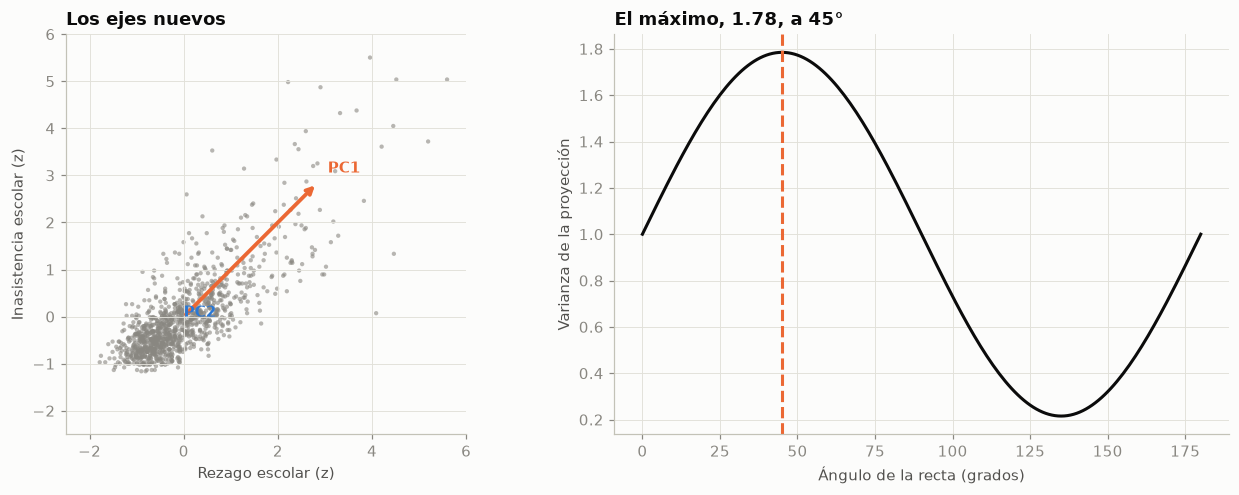

In [6]:
# la varianza de la proyección según el ángulo de la recta: el máximo es PC1
ang = np.linspace(0, 180, 181)
var = [np.mean((Z2 @ [np.cos(np.radians(a)), np.sin(np.radians(a))]) ** 2) for a in ang]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
axs[0].scatter(Z2[:, 0], Z2[:, 1], s=8, color=GRIS, alpha=.6, edgecolor='none')
for k, (col, nom) in enumerate([(NARANJA, 'PC1'), (AZUL, 'PC2')]):
    v = vec[:, k] * 3 * np.sqrt(val[k])
    axs[0].annotate('', xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=col, lw=2.5)); axs[0].text(*v * 1.08, nom, color=col, fontweight='bold')
axs[0].set(xlabel='Rezago escolar (z)', ylabel='Inasistencia escolar (z)', title='Los ejes nuevos', aspect='equal', xlim=(-2.5, 6), ylim=(-2.5, 6))
axs[1].plot(ang, var, color=TINTA); axs[1].axvline(ang[np.argmax(var)], color=NARANJA, ls='--')
axs[1].set(xlabel='Ángulo de la recta (grados)', ylabel='Varianza de la proyección', title=f'El máximo, {max(var):.2f}, a {ang[np.argmax(var)]:.0f}°')
plt.tight_layout(); plt.show()

A la izquierda, los ejes nuevos: PC1 (naranja) sigue el largo de la nube y PC2 (azul), perpendicular, su ancho. A la derecha, la varianza de la proyección según el ángulo de la recta: vale 1 a 0° (solo el rezago) y llega a su máximo, 1,78, a 45°. Esa dirección es PC1.

## 3. ¿Por qué escalar?

In [7]:
# ¿Y sin escalar? PCA sobre los porcentajes: mandan las privaciones que más varían
cruda = PCA().fit(df[PRIV])
carga_cruda = pd.Series(cruda.components_[0], index=PRIV).abs().sort_values(ascending=False)
print(f'Sin escalar, PC1 explica {cruda.explained_variance_ratio_[0]:.1%}; sus cargas más grandes:')
print(carga_cruda.head(3).round(3).to_string())
print('Desviación estándar (puntos porcentuales) de esas privaciones:', df[carga_cruda.index[:3]].std().round(1).to_dict())

Sin escalar, PC1 explica 56.4%; sus cargas más grandes:
inadecuada_elim_excretas   0.586
sin_agua_mejorada          0.548
pisos_inadecuados          0.304
Desviación estándar (puntos porcentuales) de esas privaciones: {'inadecuada_elim_excretas': 22.1, 'sin_agua_mejorada': 21.9, 'pisos_inadecuados': 16.8}


Sin escalar, PC1 explica el 56,4 %, pero no porque resuma mejor: la dominan las privaciones que más varían en puntos porcentuales (excretas, 0,586; agua, 0,548; pisos, 0,304), con desviaciones de 22,1, 21,9 y 16,8. Las privaciones de poca variación, como el trabajo infantil, casi no cuentan. **Desde aquí se trabaja con las 15 privaciones escaladas.**

## 4. ¿Cuántas componentes?

In [8]:
Z = StandardScaler().fit_transform(df[PRIV])
pca = PCA().fit(Z)
var_exp = pd.DataFrame({'autovalor': pca.explained_variance_, 'varianza explicada': pca.explained_variance_ratio_,
                        'acumulada': pca.explained_variance_ratio_.cumsum()}, index=[f'PC{i}' for i in range(1, 16)])
k_kaiser = int((var_exp.autovalor > 1).sum()); k_70 = int((var_exp.acumulada < .7).sum() + 1)
print(f'Autovalor mayor que 1: {k_kaiser} componentes · 70 % acumulado: {k_70} componentes')
var_exp.head(6)

Autovalor mayor que 1: 4 componentes · 70 % acumulado: 4 componentes


,autovalor,varianza explicada,acumulada
PC1,6.819,0.454,0.454
PC2,2.051,0.137,0.591
PC3,1.366,0.091,0.682
PC4,1.006,0.067,0.749
PC5,0.750,0.050,0.799
PC6,0.664,0.044,0.843


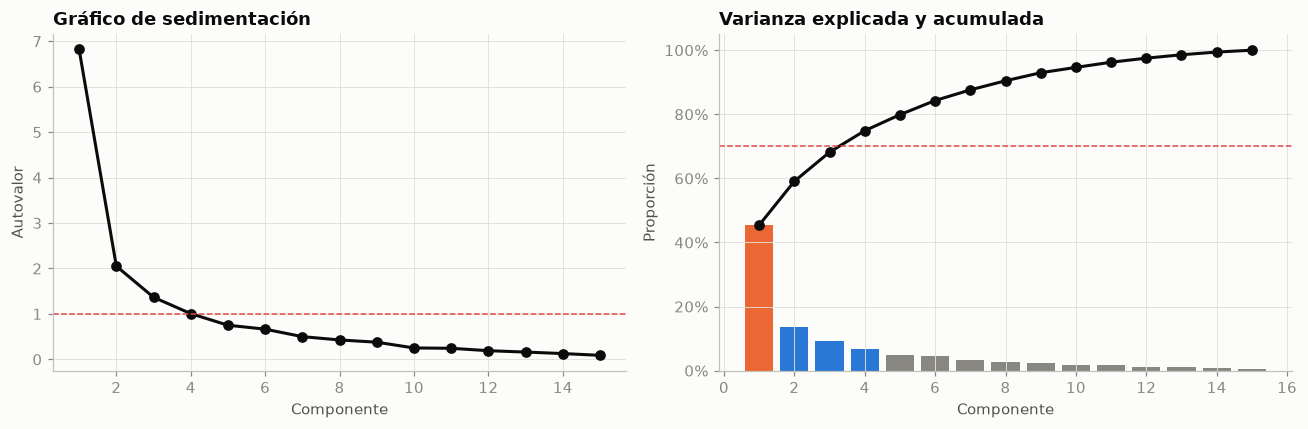

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(range(1, 16), var_exp.autovalor, 'o-', color=TINTA); axs[0].axhline(1, color=ROJO, ls='--', lw=1)
axs[0].set(title='Gráfico de sedimentación', xlabel='Componente', ylabel='Autovalor')
axs[1].bar(range(1, 16), var_exp['varianza explicada'], color=[NARANJA] + [AZUL] * 3 + [GRIS] * 11)
axs[1].plot(range(1, 16), var_exp.acumulada, 'o-', color=TINTA); axs[1].axhline(.7, color=ROJO, ls='--', lw=1)
axs[1].set(title='Varianza explicada y acumulada', xlabel='Componente', ylabel='Proporción'); axs[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

PC1 sola guarda el **45,4 %** de la información de las 15 privaciones (autovalor 6,82: vale casi lo que siete variables); PC2, el 13,7 %; PC3, el 9,1 %, y PC4, el 6,7 %. Tres criterios:

- **Autovalor mayor que 1:** 4 componentes (la cuarta vale 1,006, apenas más que una variable sola).
- **70 % acumulado:** 4 componentes, que guardan el 74,9 %.
- **El codo** del gráfico de sedimentación está en la segunda componente: después, la curva se aplana.

No hay una regla única: para un índice basta PC1; para describir los municipios, de 2 a 4.

## 5. Leer las cargas

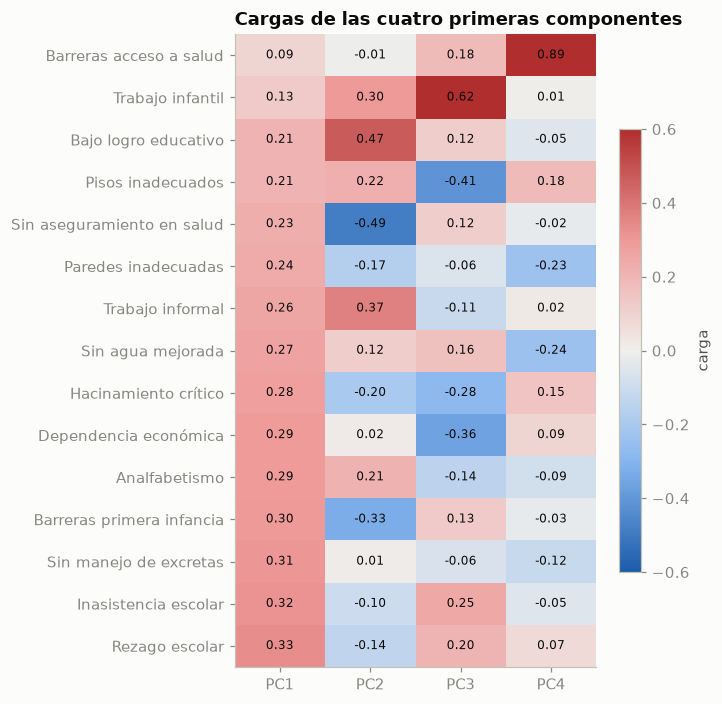

PC2, las cargas más grandes de cada lado:
Sin aseguramiento en salud   -0.490
Barreras primera infancia    -0.330
Trabajo infantil              0.300
Trabajo informal              0.370
Bajo logro educativo          0.470


In [10]:
comp = pca.components_ * np.sign(pca.components_.sum(axis=1, keepdims=True))   # signo: la suma de las cargas, positiva
cargas = pd.DataFrame(comp[:4].T, index=[NOM[p] for p in PRIV], columns=['PC1', 'PC2', 'PC3', 'PC4']).sort_values('PC1')
fig, ax = plt.subplots(figsize=(6.5, 6.5))
im = ax.imshow(cargas, cmap=DIV, vmin=-.6, vmax=.6, aspect='auto')
ax.set_xticks(range(4), cargas.columns); ax.set_yticks(range(15), cargas.index); ax.grid(False)
for i in range(15):
    for j in range(4):
        ax.text(j, i, f'{cargas.iat[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, shrink=.7, label='carga'); ax.set_title('Cargas de las cuatro primeras componentes')
plt.tight_layout(); plt.show()
print('PC2, las cargas más grandes de cada lado:'); print(cargas.PC2.sort_values().iloc[[0, 1, -3, -2, -1]].round(2).to_string())

- **PC1, la privación general:** las 15 cargas son positivas (de 0,09 a 0,33). PC1 sube cuando sube cualquier privación; las que más pesan son las de la escuela (rezago, inasistencia) y la falta de manejo de excretas.
- **PC2, un contraste:** de un lado, bajo logro educativo (0,47), trabajo informal (0,37) y trabajo infantil (0,30); del otro, sin aseguramiento en salud (−0,49) y barreras de primera infancia (−0,33). No mide cuánta privación hay sino de qué tipo: rezago educativo y laboral frente a barreras de aseguramiento y de primera infancia.
- El **signo** de cada componente es arbitrario (aquí se fijó para que la suma de las cargas sea positiva): invertido, la lectura sería la misma.

## 6. El plano de los municipios

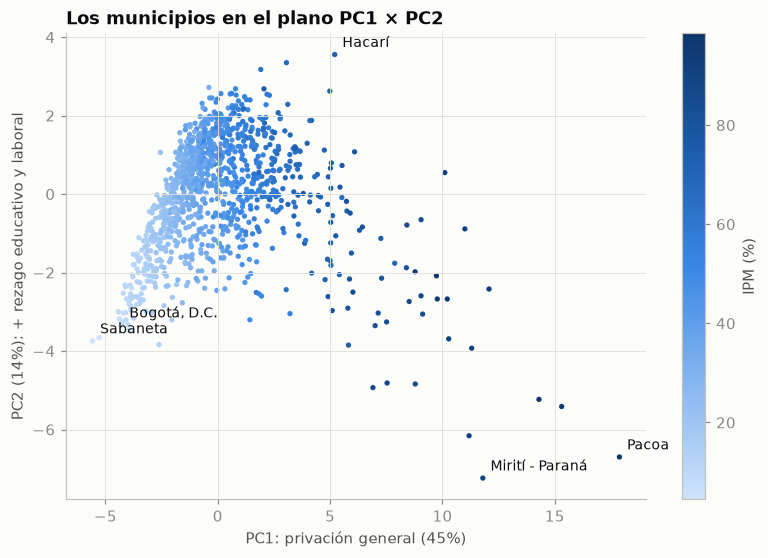

,municipio,departamento,ipm,PC1,PC2
86,Sabaneta,Antioquia,4.500,-5.579,-3.743
1114,Pacoa,Vaupés,98.400,17.877,-6.700
1093,Mirití - Paraná,Amazonas,91.200,11.798,-7.237
795,Hacarí,Norte De Santander,73.400,5.205,3.554


In [11]:
P = Z @ comp[:4].T                                  # puntajes de PC1 a PC4
df[['PC1', 'PC2', 'PC3', 'PC4']] = P
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sc = ax.scatter(df.PC1, df.PC2, c=df.ipm, cmap=SEQ, s=12, edgecolor='none')
for i in [df.PC1.idxmin(), df.PC1.idxmax(), df.PC2.idxmin(), df.PC2.idxmax(), df.index[df.municipio == 'Bogotá, D.C.'][0]]:
    ax.annotate(df.municipio[i], (df.PC1[i], df.PC2[i]), xytext=(5, 5), textcoords='offset points', fontsize=9)
fig.colorbar(sc, ax=ax, label='IPM (%)')
ax.set(xlabel=f'PC1: privación general ({var_exp.iat[0, 1]:.0%})', ylabel=f'PC2 ({var_exp.iat[1, 1]:.0%}): + rezago educativo y laboral', title='Los municipios en el plano PC1 × PC2')
plt.show()
df.loc[[df.PC1.idxmin(), df.PC1.idxmax(), df.PC2.idxmin(), df.PC2.idxmax()], ['municipio', 'departamento', 'ipm', 'PC1', 'PC2']]

Con dos números en vez de 15 se puede dibujar el país: el plano guarda el 59,1 % de la información. A la izquierda, Sabaneta (PC1 = −5,6, IPM 4,5 %); a la derecha, Pacoa (17,9, IPM 98,4 %). PC2 separa municipios con niveles parecidos: arriba, Hacarí (3,6), con más rezago educativo y laboral; abajo, Mirití-Paraná (−7,2), con más barreras de aseguramiento. El color (el IPM) crece de izquierda a derecha: PC1 es la pobreza.

## 7. Un índice compuesto

Se reescala PC1 de 0 (el menos privado) a 100 (el más privado) y se compara con el IPM oficial. La **línea base** es el promedio simple de las 15 privaciones escaladas, todas con el mismo peso.

In [12]:
df['indice'] = 100 * (df.PC1 - df.PC1.min()) / (df.PC1.max() - df.PC1.min())     # índice de 0 a 100
df['promedio'] = Z.mean(axis=1)                                                        # línea base: promedio simple de las 15 z
comp_ind = pd.DataFrame({'r con el IPM': [df.indice.corr(df.ipm), df.promedio.corr(df.ipm)],
                         'r con PC1': [1.0, df.promedio.corr(df.PC1)]}, index=['Índice con PC1', 'Promedio simple'])
print('Más alto:', ', '.join(df.nlargest(3, 'indice').municipio), '· más bajo:', ', '.join(df.nsmallest(3, 'indice').municipio))
comp_ind

Más alto: Pacoa, La Victoria, Pana Pana · más bajo: Sabaneta, Envigado, La Estrella


,r con el IPM,r con PC1
Índice con PC1,0.944,1.000
Promedio simple,0.950,0.996


El índice con PC1 correlaciona **0,944** con el IPM oficial, aunque nadie fijó los pesos a mano. Pero la línea base hace casi lo mismo: el promedio simple correlaciona 0,950 con el IPM y 0,996 con PC1. Es lo esperable cuando todas las cargas de PC1 se parecen. El aporte de PCA no es un mejor ranking: es **mostrar que domina una sola dimensión**, dar los pesos de cada privación y revelar la segunda (PC2), que el promedio esconde.

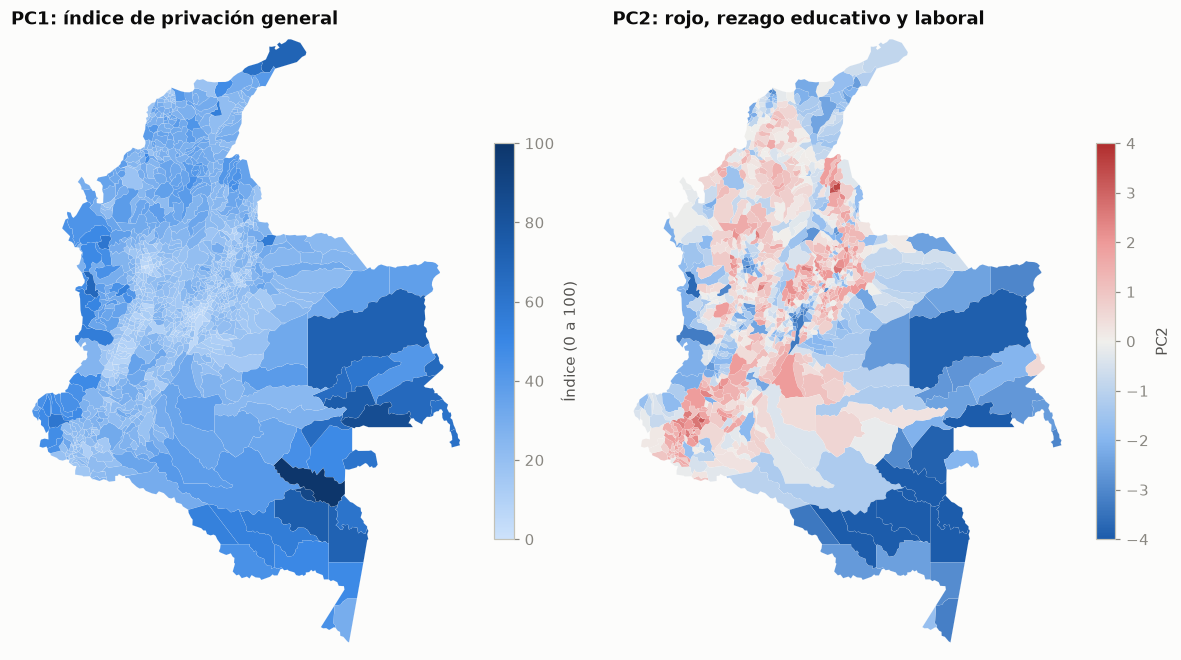

In [13]:
mapa = gpd.read_file(DATOS / 'municipios_colombia.geojson').merge(df[['cod_mpio', 'indice', 'PC2']], on='cod_mpio', how='left')
fig, axs = plt.subplots(1, 2, figsize=(11, 6.3))
mapa.plot(column='indice', cmap=SEQ, ax=axs[0], legend=True, linewidth=0.05, edgecolor='white', legend_kwds={'shrink': .6, 'label': 'Índice (0 a 100)'})
mapa.plot(column='PC2', cmap=DIV, ax=axs[1], legend=True, linewidth=0.05, edgecolor='white', vmin=-4, vmax=4, legend_kwds={'shrink': .6, 'label': 'PC2'})
axs[0].set_title('PC1: índice de privación general'); axs[1].set_title('PC2: rojo, rezago educativo y laboral')
for ax in axs: encuadre(ax)
plt.tight_layout(); plt.show()

A la izquierda, el índice (PC1): la privación general es más alta en la Amazonía, la Orinoquía, el Pacífico y La Guajira. A la derecha, PC2 cuenta otra historia: el rojo (más rezago educativo y laboral) se concentra en la zona andina, sobre todo en Nariño, Cauca, los Santanderes y Boyacá; el azul (más barreras de aseguramiento y de primera infancia), en la Amazonía, la Orinoquía y el Caribe. Dos municipios con el mismo nivel de privación pueden estar en lados opuestos de PC2.

## 8. Estabilidad

In [14]:
# ¿Cambian las cargas con otra muestra? 20 submuestras del 80 %: correlación de sus cargas con las de todos
r = np.random.default_rng(SEMILLA); sim = {'PC1': [], 'PC2': []}
for _ in range(20):
    idx = r.choice(len(Z), int(.8 * len(Z)), replace=False)
    c = PCA(2).fit(Z[idx]).components_
    for k, n in enumerate(['PC1', 'PC2']):
        sim[n].append(abs(np.corrcoef(c[k], comp[k])[0, 1]))      # el signo puede invertirse: se compara en valor absoluto
pd.DataFrame(sim).agg(['mean', 'min']).T

,mean,min
PC1,0.990,0.960
PC2,0.997,0.989


Con 20 submuestras del 80 % de los municipios, las cargas de PC1 se parecen a las de todos con una correlación promedio de 0,990 (mínimo 0,960), y las de PC2, de 0,997. Las componentes no dependen de qué municipios entren: se pueden interpretar con confianza.

## 9. PCA + K-means

En lugar de agrupar sobre las 15 privaciones, se agrupa sobre los 4 primeros puntajes, que guardan el 74,9 % de la información con menos ruido.

Silueta por k: {2: 0.408, 3: 0.286, 4: 0.275, 5: 0.282, 6: 0.276} → k = 2


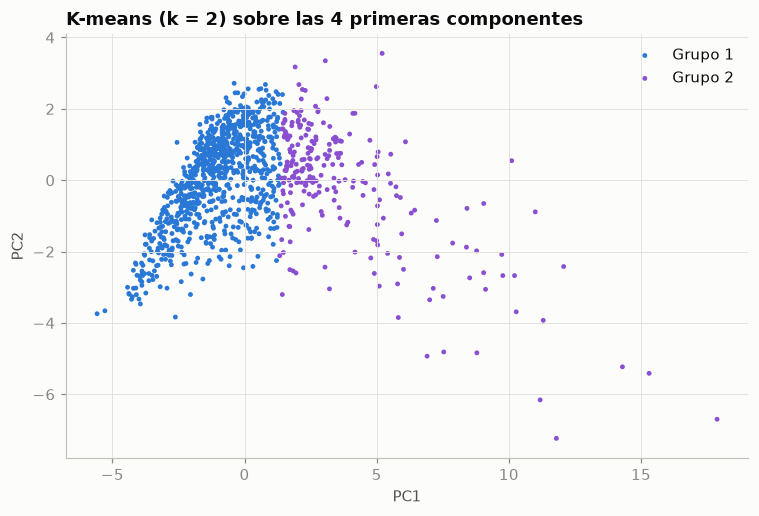

,municipios,ipm,PC1,PC2
grupo,,,,
0,878,35.161,-1.034,0.043
1,244,65.655,3.719,-0.154


In [15]:
# PCA + K-means: agrupar sobre los 4 primeros puntajes
sil = {k: silhouette_score(P, KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(P)) for k in range(2, 7)}
K = max(sil, key=sil.get)
etq = KMeans(K, n_init=10, random_state=SEMILLA).fit_predict(P)
df['grupo'] = pd.Series(etq).map({g: i for i, g in enumerate(df.groupby(etq).ipm.mean().sort_values().index)})
print('Silueta por k:', {k: round(v, 3) for k, v in sil.items()}, '→ k =', K)
fig, ax = plt.subplots(figsize=(8, 5))
cols = [AZUL, MORADO, NARANJA, AQUA, ROJO, GRIS]
for g in range(K):
    m = df.grupo == g
    ax.scatter(df.PC1[m], df.PC2[m], s=10, color=cols[g], label=f'Grupo {g + 1}', edgecolor='none')
ax.set(xlabel='PC1', ylabel='PC2', title=f'K-means (k = {K}) sobre las 4 primeras componentes'); ax.legend()
plt.show()
df.groupby('grupo').agg(municipios=('municipio', 'size'), ipm=('ipm', 'mean'), PC1=('PC1', 'mean'), PC2=('PC2', 'mean'))

La silueta más alta es con k = 2 (0,408); con 3 a 6 grupos baja a 0,28 o menos. Los dos grupos se separan sobre todo por PC1: 878 municipios con IPM promedio de 35,2 % y 244 con 65,7 %. Sobre los puntajes, K-means encuentra sobre todo el **nivel** de privación; para grupos por **tipo** de privación habría que mirar PC2 o elegir otras variables, como en la práctica de K-means.

## Conclusiones

1. **Las 15 privaciones repiten información:** 102 de 105 pares se mueven juntos, con una r promedio de 0,388.
2. **PC1 guarda el 45,4 %** y es la privación general (todas sus cargas son positivas); como índice, correlaciona 0,944 con el IPM oficial.
3. **Hay que escalar:** sin escalar, PC1 la dominan las privaciones con más varianza en puntos porcentuales.
4. **Cuántas componentes:** el autovalor mayor que 1 y el 70 % acumulado coinciden en 4 (74,9 %); el codo sugiere 2.
5. **PC2 (13,7 %) es un contraste:** rezago educativo y laboral frente a barreras de aseguramiento y de primera infancia.
6. **Línea base honesta:** el promedio simple de las 15 z hace casi lo mismo que PC1 (r = 0,996). PCA aporta la confirmación de que hay una dimensión dominante, los pesos y la segunda dimensión.
7. **Límites:** solo ve relaciones lineales, depende de escalar, pierde lo que no explica (25,1 % con 4 componentes) y sus componentes no son causas.

## Retos

1. **Solo educación.** Haga el PCA con las cinco privaciones educativas (analfabetismo, bajo logro, inasistencia, rezago, barreras de primera infancia). ¿Cuánto explica PC1? ¿Por qué más que con las 15?
2. **Sin escalar.** Compare el índice con PC1 escalado y sin escalar: ¿cuál correlaciona más con el IPM? ¿Qué municipios cambian más de puesto?
3. **Pesos del índice.** Las cargas de PC1 al cuadrado suman 1: calcule cuánto pesa cada privación en el índice y compárelo con los pesos del IPM oficial (cada dimensión pesa 20 %).
4. **Rotar la mirada.** Haga un mapa de PC3. ¿Qué privaciones lo forman y qué municipios quedan en sus extremos?
5. **Grupos por tipo.** Agrupe con K-means solo con PC2 y PC3 (sin el nivel, PC1). ¿Qué grupos aparecen? ¿Se parecen a los de la práctica de K-means?